In [1]:
import os
import csv
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from attention_numpy import softmax, entropy, scaled_dot_product_attention

DATA_PATH = os.path.join("..", "data", "IMDB Dataset.csv")   
RESULTS_PATH = "results.csv"                                


def save_result(section, name, metric, value):
    file_moi = not os.path.exists(RESULTS_PATH)
    with open(RESULTS_PATH, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if file_moi:
            w.writerow(["time", "section", "name", "metric", "value"])
        w.writerow([datetime.now().strftime("%Y-%m-%d %H:%M:%S"), section, name, metric, value])

### 17. Numerical stability

In [2]:
x = np.array([1000, 1001, 1002])

with np.errstate(all="ignore"):
    softmax_naive = np.exp(x) / np.sum(np.exp(x))
print("Không trừ max:", softmax_naive)

# Cách ổn định (trừ max)
softmax_stable = softmax(x)
print("Có trừ max:", softmax_stable, "| tổng =", softmax_stable.sum())

# Kiểm tra
print("softmax([0,1,2]) :", softmax(np.array([0, 1, 2])))

for i, v in enumerate(softmax_stable):
    save_result("17_stability", "x=[1000,1001,1002]", f"weight_{i+1}", round(float(v), 6))

Không trừ max: [nan nan nan]
Có trừ max: [0.09003057 0.24472847 0.66524096] | tổng = 0.9999999999999999
softmax([0,1,2]) : [0.09003057 0.24472847 0.66524096]


### 15. Temperature

In [3]:
# Dùng `softmax(s / T)` với T = 0.5, 1.0, 2.0 trên cùng một score vector
s = np.array([2.0, 1.0, 0.5, 0.1])
print("scores:", s)

rows = []
for T in [0.5, 1.0, 2.0]:
    w = softmax(s, temperature=T)
    rows.append({
        "Temperature": T,
        "Weights": np.round(w, 3),
        "Max weight": round(float(w.max()), 4),
        "Entropy": round(float(entropy(w)), 4),
    })
    save_result("15_temperature", f"T={T}", "max_weight", round(float(w.max()), 4))
    save_result("15_temperature", f"T={T}", "entropy", round(float(entropy(w)), 4))

pd.DataFrame(rows)

scores: [2.  1.  0.5 0.1]


,Temperature,Weights,Max weight,Entropy
0,0.5,"[0.828, 0.112, 0.041, 0.019]",0.8282,0.6068
1,1.0,"[0.575, 0.211, 0.128, 0.086]",0.5745,1.1211
2,2.0,"[0.406, 0.246, 0.192, 0.157]",0.4056,1.3181


### 16. Core implementation (re-check)

In [4]:
Q = np.array([[1, 0]])
K = np.array([[1, 0], [0, 1], [1, 1]])
V = np.array([[1, 0], [0, 2], [2, 1]])

scores, weights, context = scaled_dot_product_attention(Q, K, V)
print("scores :", scores)
print("weights:", weights, "| tổng =", weights.sum())
print("context:", context)

scores : [[0.70710678 0.         0.70710678]]
weights: [[0.40111209 0.19777581 0.40111209]] | tổng = 1.0
context: [[1.20333628 0.79666372]]


### 18. Experiment 1: Attention distribution

In [5]:
tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]

# pos  neg  film func
emb = np.array([
    [0.0, 0.0, 0.0, 1.0], # The
    [0.0, 0.0, 1.0, 0.0], # movie
    [0.0, 0.0, 0.0, 1.0], # was
    [0.6, 0.0, 0.0, 0.0], # surprisingly
    [1.0, 0.0, 0.0, 0.0], # good
    [0.0, 0.3, 0.0, 0.3], # despite
    [0.0, 0.0, 0.0, 1.0], # a
    [0.3, 0.3, 0.0, 0.0], # very
    [0.0, 0.8, 0.0, 0.0], # slow
    [0.0, 0.2, 0.3, 0.0], # beginning
])
K = V = emb

# Query A: quan tâm tới sentiment (từ tích cực / tiêu cực)
query_A = np.array([[3.0, 3.0, 0.0, 0.0]])

scores_A, weights_A, context_A = scaled_dot_product_attention(query_A, K, V)

df_A = pd.DataFrame({
    "Token": tokens,
    "Score": np.round(scores_A[0], 3),
    "Attention": np.round(weights_A[0], 3),
})
print("Tổng attention =", weights_A.sum())
df_A

Tổng attention = 1.0000000000000002


,Token,Score,Attention
0,The,0.00,0.051
1,movie,0.00,0.051
2,was,0.00,0.051
3,surprisingly,0.90,0.125
4,good,1.50,0.228
5,despite,0.45,0.080
6,a,0.00,0.051
7,very,0.90,0.125
8,slow,1.20,0.169
9,beginning,0.30,0.069


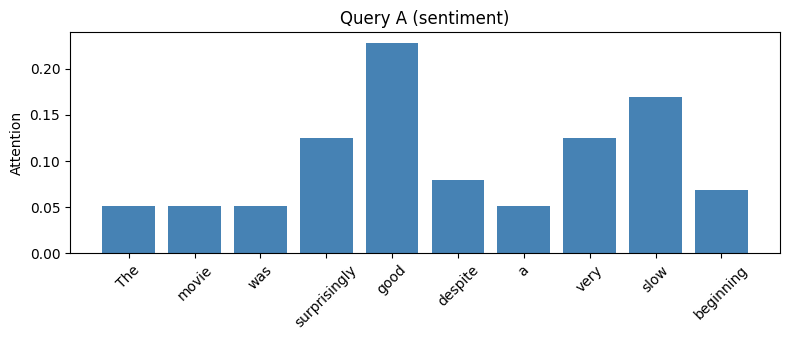

In [6]:
plt.figure(figsize=(8, 3.5))
plt.bar(tokens, weights_A[0], color="steelblue")
plt.xticks(rotation=45)
plt.ylabel("Attention")
plt.title("Query A (sentiment)")
plt.tight_layout()
plt.show()

for t, sc, w in zip(tokens, scores_A[0], weights_A[0]):
    save_result("18_exp1", f"queryA:{t}", "score", round(float(sc), 4))
    save_result("18_exp1", f"queryA:{t}", "attention", round(float(w), 4))

### 19. Experiment 2: Query thay đổi

In [7]:
# Query B: quan tâm tới chủ đề phim
query_B = np.array([[0.0, 0.0, 3.0, 0.0]])

scores_B, weights_B, context_B = scaled_dot_product_attention(query_B, K, V)

df_AB = pd.DataFrame({
    "Token": tokens,
    "Attention A (sentiment)": np.round(weights_A[0], 3),
    "Attention B (topic)": np.round(weights_B[0], 3),
})
display(df_AB)

# Top-3 token của mỗi query
for ten, w in [("A (sentiment)", weights_A[0]), ("B (topic)", weights_B[0])]:
    top3 = np.argsort(w)[::-1][:3]
    print(f"Top-3 của query {ten}:", [(tokens[i], round(float(w[i]), 3)) for i in top3])

for t, wa, wb in zip(tokens, weights_A[0], weights_B[0]):
    save_result("19_exp2", f"queryA:{t}", "attention", round(float(wa), 4))
    save_result("19_exp2", f"queryB:{t}", "attention", round(float(wb), 4))

,Token,Attention A (sentiment),Attention B (topic)
0,The,0.051,0.071
1,movie,0.051,0.319
2,was,0.051,0.071
3,surprisingly,0.125,0.071
4,good,0.228,0.071
5,despite,0.080,0.071
6,a,0.051,0.071
7,very,0.125,0.071
8,slow,0.169,0.071
9,beginning,0.069,0.112


Top-3 của query A (sentiment): [('good', 0.228), ('slow', 0.169), ('surprisingly', 0.125)]
Top-3 của query B (topic): [('movie', 0.319), ('beginning', 0.112), ('slow', 0.071)]


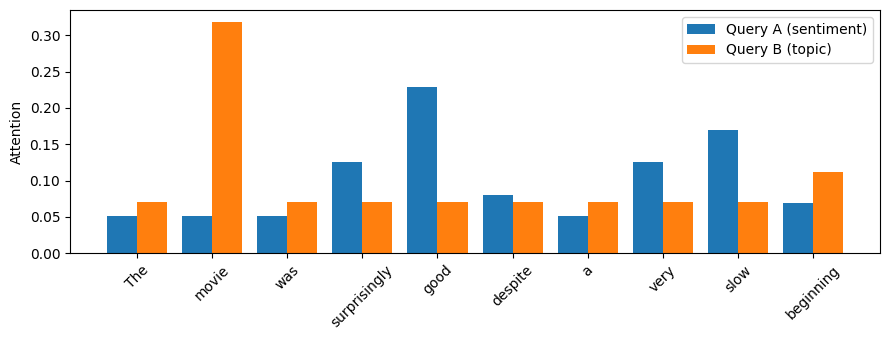

In [8]:
x_pos = np.arange(len(tokens))
plt.figure(figsize=(9, 3.5))
plt.bar(x_pos - 0.2, weights_A[0], width=0.4, label="Query A (sentiment)")
plt.bar(x_pos + 0.2, weights_B[0], width=0.4, label="Query B (topic)")
plt.xticks(x_pos, tokens, rotation=45)
plt.ylabel("Attention")
plt.legend()
plt.tight_layout()
plt.show()

### 22. Attention matrix

In [9]:
tokens_s = ["I", "like", "cats"]
X = np.array([
    [1.0, 0.0], # I
    [0.5, 1.0], # like
    [0.0, 1.0], # cats
])

S, A, C = scaled_dot_product_attention(X, X, X)

print("Attention matrix A:")
display(pd.DataFrame(np.round(A, 3), index=tokens_s, columns=tokens_s))
print("Tổng mỗi hàng:", A.sum(axis=1))

Attention matrix A:


,I,like,cats
I,0.456,0.320,0.225
like,0.243,0.412,0.345
cats,0.198,0.401,0.401


Tổng mỗi hàng: [1. 1. 1.]


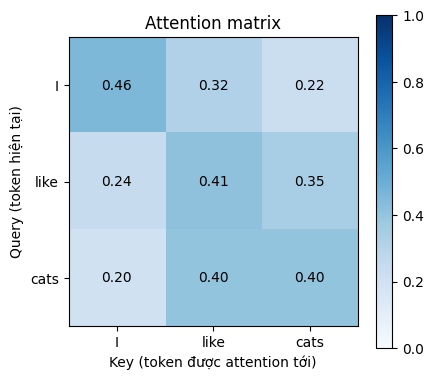

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(tokens_s)))
ax.set_yticks(range(len(tokens_s)))
ax.set_xticklabels(tokens_s)
ax.set_yticklabels(tokens_s)
ax.set_xlabel("Key (token được attention tới)")
ax.set_ylabel("Query (token hiện tại)")
for i in range(len(tokens_s)):
    for j in range(len(tokens_s)):
        ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.title("Attention matrix")
plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=150)
plt.show()

for i, ti in enumerate(tokens_s):
    for j, tj in enumerate(tokens_s):
        save_result("22_attention_matrix", f"{ti}->{tj}", "attention", round(float(A[i, j]), 4))

### 23. Experiment 3: Attention visualization

In [11]:
import torch
import torch.nn as nn

s1 = ["The", "cat", "that", "I", "adopted", "yesterday", "is", "sleeping"]
s2 = ["The", "book", "that", "I", "bought", "yesterday", "was", "expensive"]

D = 8
torch.manual_seed(0)
vocab_23 = sorted(set(s1 + s2))
word_id = {w: i for i, w in enumerate(vocab_23)}
emb_23 = nn.Embedding(len(vocab_23), D) # cùng từ -> cùng vector
mha_23 = nn.MultiheadAttention(embed_dim=D, num_heads=1, batch_first=True)


def self_attention_demo(tokens):
    ids = torch.tensor([[word_id[w] for w in tokens]]) # (1, T)
    x = emb_23(ids) # (1, T, D)
    with torch.no_grad():
        _, A = mha_23(x, x, x, need_weights=True) # A: (1, T, T)
    return A[0].numpy()


A1 = self_attention_demo(s1)
A2 = self_attention_demo(s2)

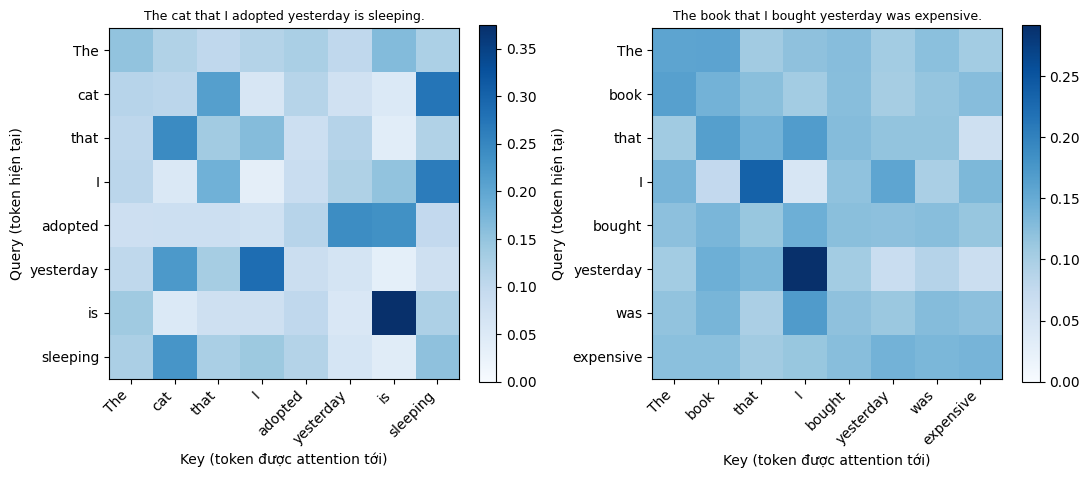

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, A, toks in [(axes[0], A1, s1), (axes[1], A2, s2)]:
    im = ax.imshow(A, cmap="Blues", vmin=0, vmax=A.max())
    ax.set_xticks(range(len(toks)))
    ax.set_yticks(range(len(toks)))
    ax.set_xticklabels(toks, rotation=45, ha="right")
    ax.set_yticklabels(toks)
    ax.set_xlabel("Key (token được attention tới)")
    ax.set_ylabel("Query (token hiện tại)")
    fig.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_title("The cat that I adopted yesterday is sleeping.", fontsize=9)
axes[1].set_title("The book that I bought yesterday was expensive.", fontsize=9)
plt.tight_layout()
plt.savefig("attention_heatmap_exp3.png", dpi=150)
plt.show()

In [13]:
# Với 3 token cat / adopted / sleeping: mỗi token attention tới những token nào nhiều nhất?
def top_attended(A, toks, token, k=3):
    i = toks.index(token)
    top = np.argsort(A[i])[::-1][:k]
    return [(toks[j], round(float(A[i, j]), 3)) for j in top]


for toks, A, name in [(s1, A1, "câu 1"), (s2, A2, "câu 2")]:
    chon = ["cat", "adopted", "sleeping"] if name == "câu 1" else ["book", "bought", "expensive"]
    for t in chon:
        top = top_attended(A, toks, t)
        print(f"[{name}] {t:>9} -> {top}")
        save_result("23_exp3", f"{name}:{t}", "top3_attended", " | ".join(f"{w}:{v}" for w, v in top))

[câu 1]       cat -> [('sleeping', 0.274), ('that', 0.211), ('adopted', 0.113)]
[câu 1]   adopted -> [('yesterday', 0.24), ('is', 0.234), ('adopted', 0.111)]
[câu 1]  sleeping -> [('cat', 0.228), ('sleeping', 0.155), ('I', 0.141)]
[câu 2]      book -> [('The', 0.164), ('book', 0.139), ('expensive', 0.125)]
[câu 2]    bought -> [('I', 0.145), ('book', 0.135), ('was', 0.125)]
[câu 2] expensive -> [('yesterday', 0.14), ('expensive', 0.138), ('was', 0.134)]


### 24. Experiment 4: RNN context vs Attention context

In [14]:
import re
import time
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
MAX_LEN = 200 # cắt review dài hơn 200 token
VOCAB_SIZE = 20000
EMB_DIM = 64
HID_DIM = 64
BATCH_SIZE = 64
EPOCHS = 3
LR = 1e-3
SAMPLE_SIZE = None 

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


In [15]:
df = pd.read_csv(DATA_PATH)                  
if SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=SEED)
df["label"] = (df["sentiment"] == "positive").astype(int)


def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z']+", text)


df["tokens"] = df["review"].apply(tokenize)

# train/ val/ test = 80/ 10/ 10 
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED, stratify=temp_df["label"])
print("train / val / test:", len(train_df), len(val_df), len(test_df))

# Vocab (xây từ tập train) 
counter = Counter(w for toks in train_df["tokens"] for w in toks)
word2idx = {"<pad>": 0, "<unk>": 1}
for w, _ in counter.most_common(VOCAB_SIZE - 2):
    word2idx[w] = len(word2idx)
print("vocab size:", len(word2idx))


def encode(tokens):
    ids = [word2idx.get(w, 1) for w in tokens[:MAX_LEN]]   
    if len(ids) == 0:
        ids = [1]
    return ids + [0] * (MAX_LEN - len(ids)) # pad bằng 0


def to_loader(part, shuffle):
    X = torch.tensor([encode(t) for t in part["tokens"]], dtype=torch.long)
    y = torch.tensor(part["label"].values, dtype=torch.float)
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = to_loader(train_df, True)
val_loader = to_loader(val_df, False)
test_loader = to_loader(test_df, False)

train / val / test: 40000 5000 5000
vocab size: 20000


In [16]:
class LSTMClassifier(nn.Module):
    """Embedding -> LSTM -> hidden state cuối -> Linear"""

    def __init__(self, vocab_size, emb_dim, hid_dim):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hid_dim, batch_first=True)
        self.fc = nn.Linear(hid_dim, 1)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu() # độ dài thật (không tính pad)
        e = self.emb(x)
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed) # h_n: hidden state cuối
        return self.fc(h_n[-1]).squeeze(1)


class SelfAttentionClassifier(nn.Module):
    """Embedding -> Self-Attention (nn.MultiheadAttention, 1 head) -> trung bình context -> Linear"""

    def __init__(self, vocab_size, emb_dim):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.attn = nn.MultiheadAttention(embed_dim=emb_dim, num_heads=1, batch_first=True)
        self.fc = nn.Linear(emb_dim, 1)

    def forward(self, x, return_attn=False):
        pad_mask = (x == 0) # (B, T), True = pad -> bị bỏ qua
        e = self.emb(x)
        C, A = self.attn(e, e, e, key_padding_mask=pad_mask, need_weights=True) # C: (B,T,E), A: (B,T,T)

        m = (~pad_mask).unsqueeze(-1).float()
        pooled = (C * m).sum(dim=1) / m.sum(dim=1).clamp(min=1) # trung bình trên token thật
        logit = self.fc(pooled).squeeze(1)
        return (logit, A) if return_attn else logit

In [17]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def predict_loader(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            prob = torch.sigmoid(model(xb.to(device))).cpu()
            y_pred += (prob > 0.5).int().tolist()
            y_true += yb.int().tolist()
    return y_true, y_pred


def train_model(model, name):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()

    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)
        yv, pv = predict_loader(model, val_loader)
        print(f"[{name}] epoch {epoch+1}/{EPOCHS} | loss {total_loss/len(train_df):.4f} | val acc {accuracy_score(yv, pv):.4f}")
    train_time = time.time() - start

    y_true, y_pred = predict_loader(model, test_loader)
    result = {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "F1": round(f1_score(y_true, y_pred), 4),
        "Training time (s)": round(train_time, 1),
        "Parameters": count_params(model),
    }
    for metric, value in result.items():
        if metric != "Model":
            save_result("24_exp4", name, metric, value)
    return result, y_true, y_pred

In [18]:
torch.manual_seed(SEED)
lstm_model = LSTMClassifier(len(word2idx), EMB_DIM, HID_DIM)
res_lstm, yt_lstm, yp_lstm = train_model(lstm_model, "LSTM")

torch.manual_seed(SEED)
attn_model = SelfAttentionClassifier(len(word2idx), EMB_DIM)
res_attn, yt_attn, yp_attn = train_model(attn_model, "Attention")

pd.DataFrame([res_lstm, res_attn])

[LSTM] epoch 1/3 | loss 0.6208 | val acc 0.7610
[LSTM] epoch 2/3 | loss 0.5727 | val acc 0.7006
[LSTM] epoch 3/3 | loss 0.4409 | val acc 0.8318
[Attention] epoch 1/3 | loss 0.4709 | val acc 0.8364
[Attention] epoch 2/3 | loss 0.3220 | val acc 0.8602
[Attention] epoch 3/3 | loss 0.2652 | val acc 0.8760


,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.8144,0.8164,1235.7,1313345
1,Attention,0.8692,0.8680,103.1,1296705


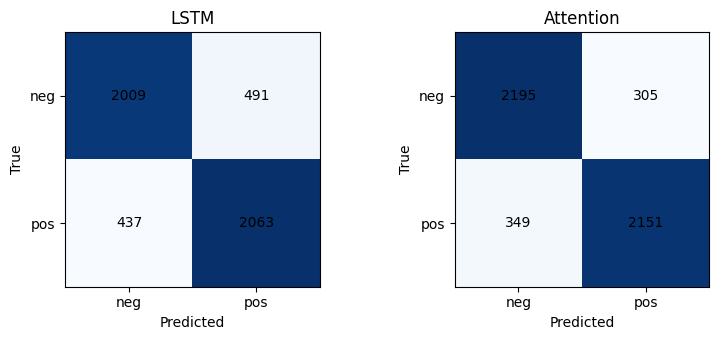

In [19]:
# Confusion matrix của 2 model trên tập test
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, name, yt, yp in [(axes[0], "LSTM", yt_lstm, yp_lstm), (axes[1], "Attention", yt_attn, yp_attn)]:
    cm = confusion_matrix(yt, yp)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["neg", "pos"])
    ax.set_yticklabels(["neg", "pos"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

### 25. Experiment 5: Sequence length và computational cost

In [20]:
import torch.nn.functional as F

d = 64
rows = []
for T in [10, 100, 500, 1000]:
    Q = K = V = torch.randn(1, T, d)

    with torch.no_grad():
        F.scaled_dot_product_attention(Q, K, V) # chạy thử 1 lần
        t0 = time.perf_counter()
        for _ in range(5):
            F.scaled_dot_product_attention(Q, K, V)
        ms = (time.perf_counter() - t0) / 5 * 1000

    rows.append({
        "Sequence length": T,
        "Attention matrix": f"({T}x{T})",
        "Số phần tử": T * T,
        "Bộ nhớ matrix (MB, float32)": round(T * T * 4 / 1e6, 3),
        "Thời gian PyTorch (ms)": round(ms, 2),
    })
    save_result("25_exp5", f"T={T}", "num_elements", T * T)
    save_result("25_exp5", f"T={T}", "time_ms", round(ms, 2))

# Thêm T = 10000, chỉ tính số phần tử vì matrix quá lớn để đo
rows.append({
    "Sequence length": 10000,
    "Attention matrix": "(10000x10000)",
    "Số phần tử": 10000 * 10000,
    "Bộ nhớ matrix (MB, float32)": round(10000 * 10000 * 4 / 1e6, 3),
    "Thời gian PyTorch (ms)": "không đo",
})
save_result("25_exp5", "T=10000", "num_elements", 10000 * 10000)

pd.DataFrame(rows)

,Sequence length,Attention matrix,Số phần tử,"Bộ nhớ matrix (MB, float32)",Thời gian PyTorch (ms)
0,10,(10x10),100,0.00,0.02
1,100,(100x100),10000,0.04,0.13
2,500,(500x500),250000,1.00,0.32
3,1000,(1000x1000),1000000,4.00,2.2
4,10000,(10000x10000),100000000,400.00,không đo


### 26. Application: Context-aware sentiment

In [21]:
def predict_sentence(model, sentence, with_attn=False):
    tokens = tokenize(sentence)[:MAX_LEN]
    x = torch.tensor([encode(tokenize(sentence))], dtype=torch.long).to(device)
    model.eval()
    with torch.no_grad():
        if with_attn:
            logit, A = model(x, return_attn=True)
            A = A[0, :len(tokens), :len(tokens)].cpu().numpy()
        else:
            logit, A = model(x), None
    prob_pos = torch.sigmoid(logit).item()
    return tokens, prob_pos, A


test_sentences = [
    ("I like this movie.", "positive"),
    ("I do not like this movie.", "negative"),
    ("I thought this movie would be bad, but it was actually excellent.", "positive"),
]

rows = []
for sent, expected in test_sentences:
    _, p_lstm, _ = predict_sentence(lstm_model, sent)
    _, p_attn, _ = predict_sentence(attn_model, sent)
    pred_lstm = "positive" if p_lstm > 0.5 else "negative"
    pred_attn = "positive" if p_attn > 0.5 else "negative"
    rows.append({
        "Sentence": sent,
        "Expected": expected,
        "LSTM prob(pos)": round(p_lstm, 3),
        "LSTM pred": pred_lstm,
        "Attn prob(pos)": round(p_attn, 3),
        "Attn pred": pred_attn,
        "Attn đúng?": pred_attn == expected,
    })
    save_result("26_application", sent, "lstm_prob_pos", round(p_lstm, 4))
    save_result("26_application", sent, "attention_prob_pos", round(p_attn, 4))

pd.DataFrame(rows)

,Sentence,Expected,LSTM prob(pos),LSTM pred,Attn prob(pos),Attn pred,Attn đúng?
0,I like this movie.,positive,0.392,negative,0.233,negative,False
1,I do not like this movie.,negative,0.240,negative,0.001,negative,True
2,"I thought this movie would be bad, but it was ...",positive,0.404,negative,0.975,positive,True


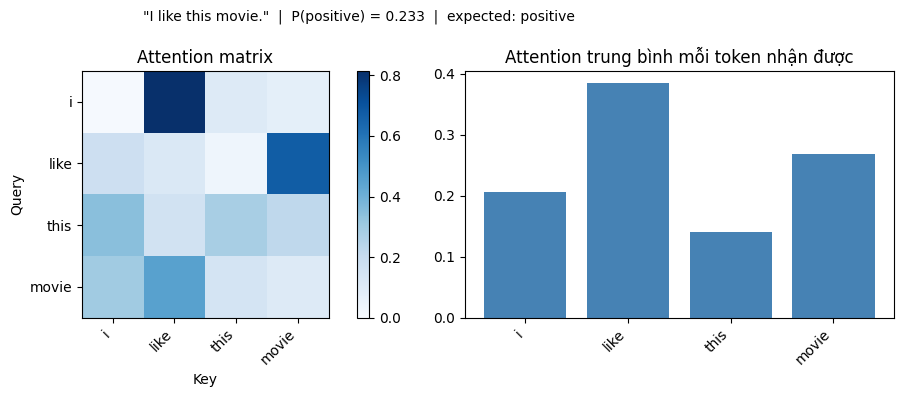

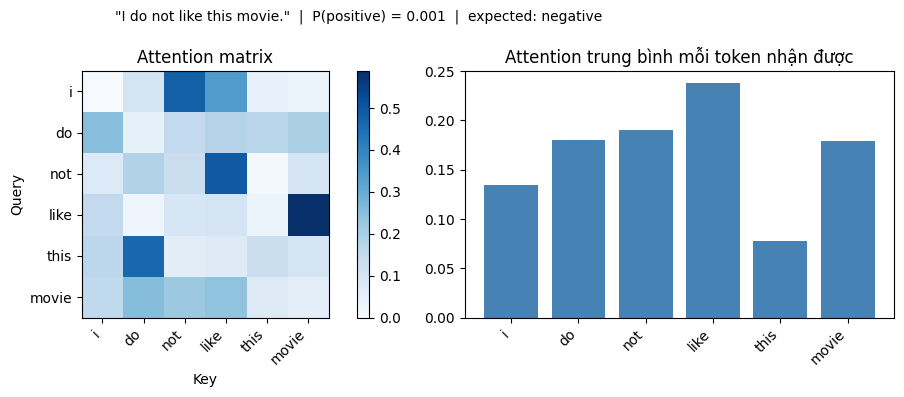

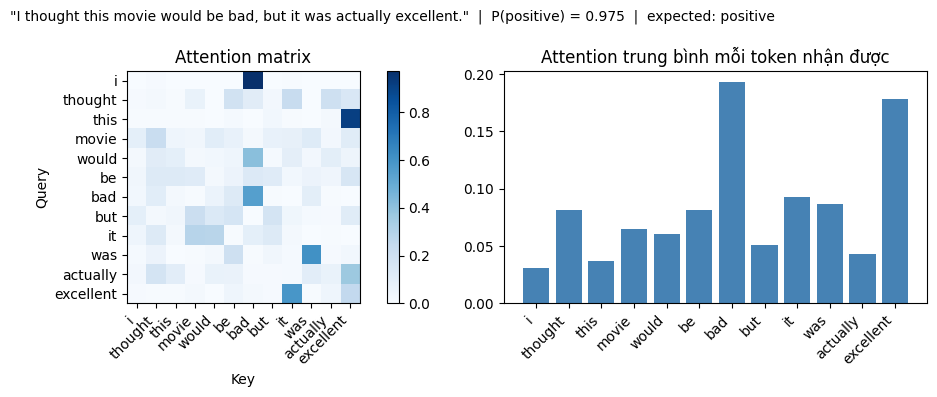

In [22]:
for i, (sent, expected) in enumerate(test_sentences):
    tokens, prob, A = predict_sentence(attn_model, sent, with_attn=True)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})

    im = ax1.imshow(A, cmap="Blues", vmin=0, vmax=A.max())
    ax1.set_xticks(range(len(tokens)))
    ax1.set_yticks(range(len(tokens)))
    ax1.set_xticklabels(tokens, rotation=45, ha="right")
    ax1.set_yticklabels(tokens)
    ax1.set_xlabel("Key")
    ax1.set_ylabel("Query")
    ax1.set_title("Attention matrix")
    fig.colorbar(im, ax=ax1, fraction=0.046)

    ax2.bar(range(len(tokens)), A.mean(axis=0), color="steelblue")   # attention trung bình mỗi token nhận được
    ax2.set_xticks(range(len(tokens)))
    ax2.set_xticklabels(tokens, rotation=45, ha="right")
    ax2.set_title("Attention trung bình mỗi token nhận được")

    fig.suptitle(f'"{sent}"  |  P(positive) = {prob:.3f}  |  expected: {expected}', fontsize=10)
    plt.tight_layout()
    plt.savefig(f"attention_app_{i+1}.png", dpi=150)
    plt.show()

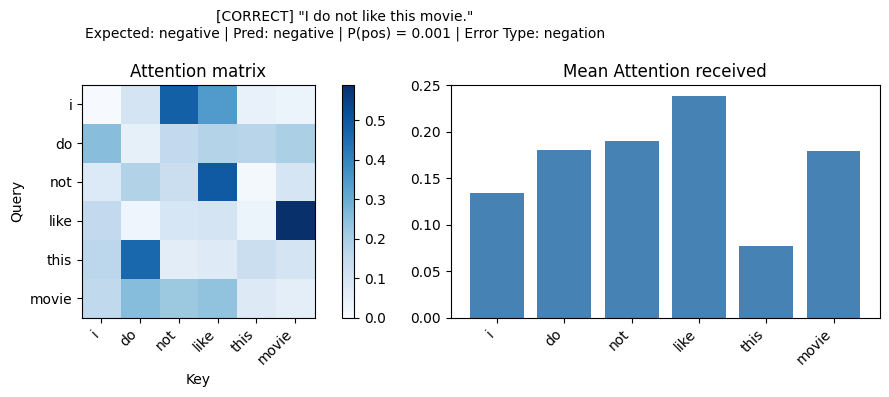

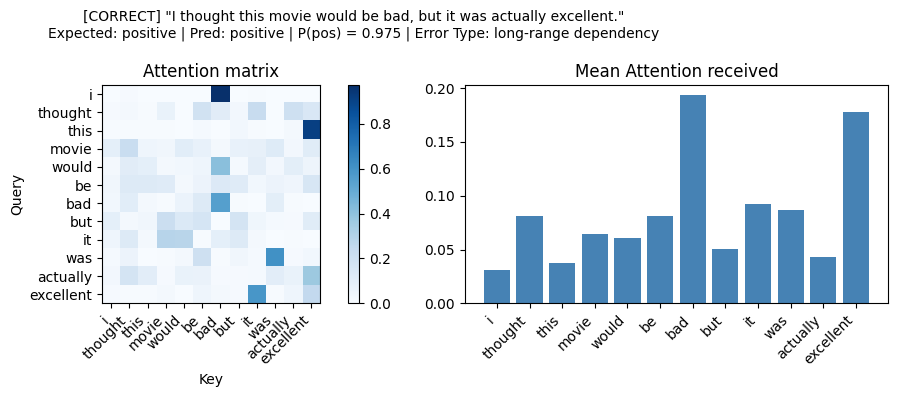

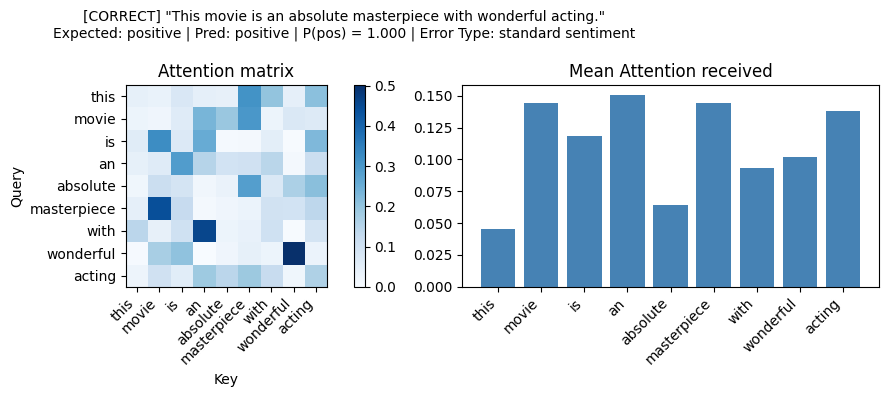

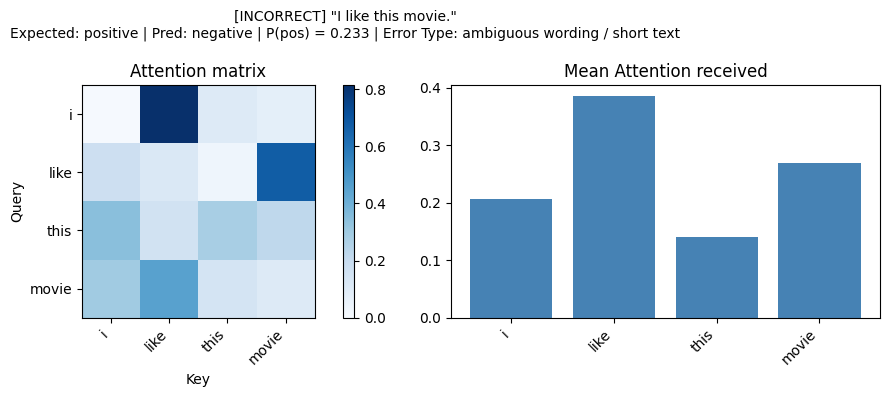

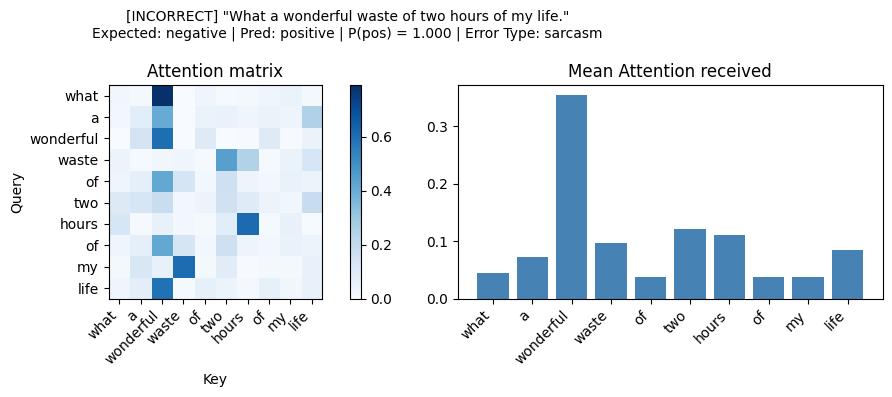

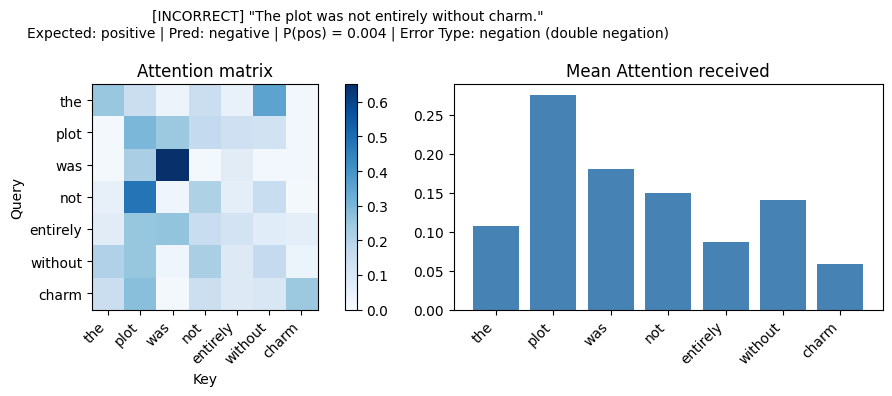

,No,Sentence,Expected,Pred,P(pos),Correct?,Category
0,1,I do not like this movie.,negative,negative,0.001,True,negation
1,2,"I thought this movie would be bad, but it was ...",positive,positive,0.975,True,long-range dependency
2,3,This movie is an absolute masterpiece with won...,positive,positive,1.000,True,standard sentiment
3,4,I like this movie.,positive,negative,0.233,False,ambiguous wording / short text
4,5,What a wonderful waste of two hours of my life.,negative,positive,1.000,False,sarcasm
5,6,The plot was not entirely without charm.,positive,negative,0.004,False,negation (double negation)


In [ ]:
error_analysis_sentences = [
    {
        "sent": "I do not like this movie.",
        "expected": "negative",
        "category": "negation",
        "group": "correct"
    },
    {
        "sent": "I thought this movie would be bad, but it was actually excellent.",
        "expected": "positive",
        "category": "long-range dependency",
        "group": "correct"
    },
    {
        "sent": "This movie is an absolute masterpiece with wonderful acting.",
        "expected": "positive",
        "category": "standard sentiment",
        "group": "correct"
    },

    {
        "sent": "I like this movie.",
        "expected": "positive",
        "category": "ambiguous wording / short text",
        "group": "incorrect"
    },
    {
        "sent": "What a wonderful waste of two hours of my life.",
        "expected": "negative",
        "category": "sarcasm",
        "group": "incorrect"
    },
    {
        "sent": "The plot was not entirely without charm.",
        "expected": "positive",
        "category": "negation (double negation)",
        "group": "incorrect"
    }
]

ea_results = []

for idx, item in enumerate(error_analysis_sentences, 1):
    sent = item["sent"]
    expected = item["expected"]
    cat = item["category"]
    
    tokens, prob, A = predict_sentence(attn_model, sent, with_attn=True)
    pred = "positive" if prob > 0.5 else "negative"
    is_correct = (pred == expected)
    
    # Lấy top-3 token nhận được attention trung bình cao nhất
    mean_attn = A.mean(axis=0)
    top_indices = mean_attn.argsort()[::-1][:3]
    top_tokens = [(tokens[i], round(float(mean_attn[i]), 3)) for i in top_indices]
    
    ea_results.append({
        "No": idx,
        "Sentence": sent,
        "Expected": expected,
        "Pred": pred,
        "P(pos)": round(prob, 3),
        "Correct?": is_correct,
        "Category": cat,
        "Top-3 Attended Tokens": top_tokens
    })
    
    # Vẽ biểu đồ Attention Matrix và Phân phối Attention
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
    
    im = ax1.imshow(A, cmap="Blues", vmin=0, vmax=A.max())
    ax1.set_xticks(range(len(tokens)))
    ax1.set_yticks(range(len(tokens)))
    ax1.set_xticklabels(tokens, rotation=45, ha="right")
    ax1.set_yticklabels(tokens)
    ax1.set_xlabel("Key")
    ax1.set_ylabel("Query")
    ax1.set_title("Attention matrix")
    fig.colorbar(im, ax=ax1, fraction=0.046)
    
    ax2.bar(range(len(tokens)), mean_attn, color="steelblue")
    ax2.set_xticks(range(len(tokens)))
    ax2.set_xticklabels(tokens, rotation=45, ha="right")
    ax2.set_title("Mean Attention received")
    
    status = "CORRECT" if is_correct else "INCORRECT"
    fig.suptitle(f'[{status}] "{sent}"\nExpected: {expected} | Pred: {pred} | P(pos) = {prob:.3f} | Error Type: {cat}', fontsize=10)
    plt.tight_layout()
    plt.savefig(f"error_analysis_{idx}.png", dpi=150)
    plt.show()

# Hiển thị bảng tổng hợp
df_ea = pd.DataFrame(ea_results)
df_ea[["No", "Sentence", "Expected", "Pred", "P(pos)", "Correct?", "Category"]]